# 09 · All results and the answers to RQ1-RQ4

This notebook needs no GPU and no images. It reads every experiment's record (`results/<exp>/record.json`) and the
saved tables, builds the experiment log `results/experiments.csv`, and answers the four research questions with the
numbers side by side.

**How the numbers were produced.** All models were scored by the same KITTI evaluator (AP at IoU 0.5, 40 recall
points, Moderate difficulty, DontCare regions ignored). The **primary metric** is the mean AP of Car, Pedestrian and
Cyclist. Every choice was made on the **validation** split; each finished model was scored on the **test** split
(1,543 images from drives no model was trained on) exactly once.

**Setup.** Runs on the laptop, from the `notebooks/` folder. Imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`). Results and weights are read from the project's `results/` and `weights/` folders,
which hold the outputs of the Kaggle notebooks 01-07.

In [1]:
import os, sys, json, time, platform, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # kitti_common.py sits next to this notebook (written by 00_common)
from kitti_common import *
from kitti_common import _save    # figure helper (underscore names are not exported by *)
import cv2
seed_everything()
print("local" if not ON_KAGGLE else "Kaggle", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| project root:", OUT)

C:\Users\Fizza\anaconda3\envs\torch-gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


local | GPU: NVIDIA GeForce RTX 3050 Laptop GPU | project root: C:\Users\Fizza\Downloads\DSTT\Project\KITTI-Obstacle-Detection


## 1. The experiment log

In [2]:
ORDER = ["E0", "E2", "E3", "E4a_ref", "E4b_img960", "E4c_rfs", "E4d_combined", "E4e_lr002", "FINAL", "E5", "E6", "E7", "E8"]
recs = {e: load_record(e) for e in ORDER}
missing = [e for e, r in recs.items() if r is None]
assert not missing, f"missing records: {missing}"

COLS = {"description": "description", "research_question": "RQ", "imgsz": "image size", "epochs_run": "epochs run",
        "best_epoch": "best epoch", "train_hours": "train hours", "val_primary_mAP50_mod": "val primary",
        "test_primary_mAP50_mod": "test primary", "test_AP50_Car_moderate": "test Car",
        "test_AP50_Pedestrian_moderate": "test Pedestrian", "test_AP50_Cyclist_moderate": "test Cyclist",
        "test_mAP50_all8": "test mAP@0.5 (8 classes)", "test_AP70_Car_mod": "test Car AP@0.7"}
log = pd.DataFrame([{"exp_id": e, **{c: r.get(c) for c in COLS}} for e, r in recs.items()]).set_index("exp_id")
# E5 is scored on the random split: its val/test columns are the random-split numbers
speed = pd.read_csv(RESULTS / "E7" / "speed.csv")
for prec in ["FP32", "FP16"]:
    log[f"fps_{prec}"] = log.index.map(speed[speed.precision == prec].set_index("model").fps)
log.loc["E0", f"fps_FP16"] = log.loc["E2", "fps_FP16"]; log.loc["E0", "fps_FP32"] = log.loc["E2", "fps_FP32"]
log.loc["E5", f"fps_FP16"] = log.loc["FINAL", "fps_FP16"]; log.loc["E5", "fps_FP32"] = log.loc["FINAL", "fps_FP32"]
log.rename(columns=COLS).to_csv(RESULTS / "experiments.csv")
log.rename(columns=COLS).drop(columns=["description"]).round(3)

,RQ,image size,epochs run,best epoch,train hours,val primary,test primary,test Car,test Pedestrian,test Cyclist,test mAP@0.5 (8 classes),test Car AP@0.7,fps_FP32,fps_FP16
exp_id,,,,,,,,,,,,,,
E0,RQ1,640,0.0,NaN,0.000,0.473,0.542,0.930,0.687,0.008,0.264,0.720,52.91,54.79
E2,"RQ1, RQ2",640,12.0,2.0,0.214,0.697,0.716,0.965,0.744,0.441,0.429,0.867,52.91,54.79
E3,RQ2,800/1333,10.0,2.0,1.792,0.812,0.854,0.968,0.814,0.779,0.516,0.932,10.89,13.95
E4a_ref,tuning,640,12.0,2.0,0.218,0.670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E4b_img960,tuning,960,12.0,2.0,0.432,0.787,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E4c_rfs,tuning,640,12.0,2.0,0.269,0.682,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E4d_combined,tuning,960,25.0,18.0,1.133,0.732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
E4e_lr002,tuning,960,13.0,3.0,0.601,0.779,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FINAL,all,960,13.0,3.0,0.624,0.758,0.799,0.967,0.797,0.631,0.526,0.935,45.94,59.79


## 2. The models side by side (test set)

The finished models on the same test set. E5 is left out here: it was trained and tested on a different (random)
split, so its numbers are not comparable (see RQ3).

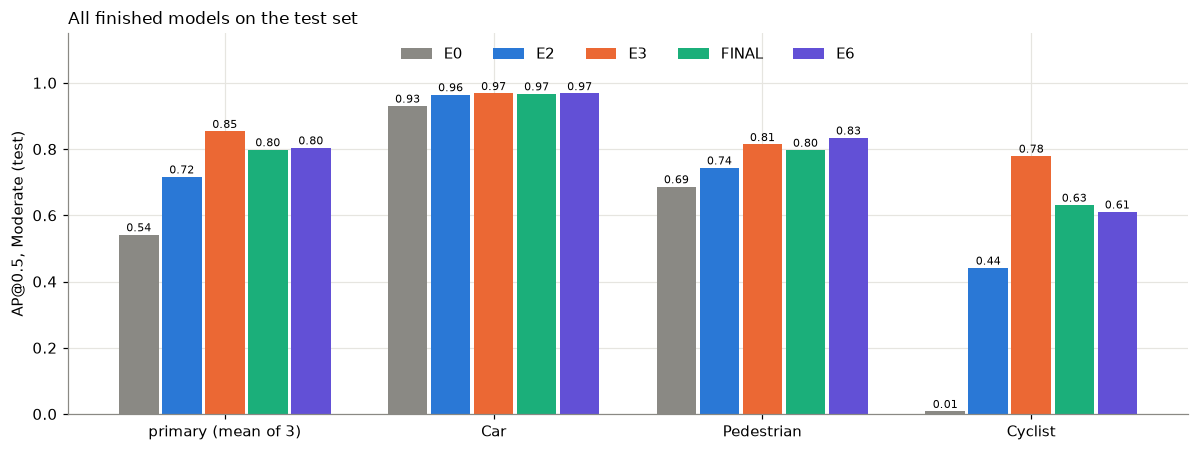

,primary,Car,Pedestrian,Cyclist
E0,0.542,0.930,0.687,0.008
E2,0.716,0.965,0.744,0.441
E3,0.854,0.968,0.814,0.779
FINAL,0.799,0.967,0.797,0.631
E6,0.804,0.968,0.834,0.611


In [3]:
MODELS = ["E0", "E2", "E3", "FINAL", "E6"]
metric = {"primary": "test_primary_mAP50_mod", "Car": "test_AP50_Car_moderate",
          "Pedestrian": "test_AP50_Pedestrian_moderate", "Cyclist": "test_AP50_Cyclist_moderate"}
tab = pd.DataFrame({m: {k: recs[m][v] for k, v in metric.items()} for m in MODELS}).T
fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.8 / len(MODELS)
xs = np.arange(len(metric))
for i, m in enumerate(MODELS):
    bars = ax.bar(xs + (i - (len(MODELS) - 1) / 2) * w, tab.loc[m], w * 0.92, color=MODEL_C[m], label=m)
    for b_, v in zip(bars, tab.loc[m]):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=7.5)
ax.set_xticks(xs, ["primary (mean of 3)", "Car", "Pedestrian", "Cyclist"]); ax.set_ylim(0, 1.15)
ax.set_ylabel("AP@0.5, Moderate (test)"); ax.legend(ncol=5, loc="upper center")
ax.set_title("All finished models on the test set", loc="left")
_save(fig, "summary", "models_test")
tab.round(3)

## 3. RQ1: does training on KITTI help, compared with a general-purpose pretrained detector?

E0 is YOLOv8s with its COCO weights only (COCO classes mapped to KITTI classes). E2 is the same network fine-tuned on
KITTI, and FINAL is the tuned version.

In [4]:
rq1 = tab.loc[["E0", "E2", "FINAL"]].T
rq1["gain E0 -> E2"] = rq1.E2 - rq1.E0
rq1["gain E0 -> FINAL"] = rq1.FINAL - rq1.E0
rq1.round(3)

,E0,E2,FINAL,gain E0 -> E2,gain E0 -> FINAL
primary,0.542,0.716,0.799,0.175,0.257
Car,0.930,0.965,0.967,0.034,0.037
Pedestrian,0.687,0.744,0.797,0.057,0.110
Cyclist,0.008,0.441,0.631,0.433,0.623


## 4. RQ2: accuracy against speed

Accuracy from the test set; speed measured on the laptop GPU in notebook 08 (batch 1, FP16).

In [5]:
s16 = speed[speed.precision == "FP16"].set_index("model")
s32 = speed[speed.precision == "FP32"].set_index("model")
rq2 = pd.DataFrame({"test primary": tab.primary, "test Cyclist": tab.Cyclist,
                    "FPS (FP16)": s16.fps, "FPS (FP32)": s32.fps, "ms per image (FP16)": s16.ms_p50,
                    "train hours": pd.Series({m: recs[m].get("train_hours") for m in tab.index})}).loc[["E2", "E3", "FINAL", "E6"]]
rq2["real time (>= 30 FPS, FP16)"] = rq2["FPS (FP16)"] >= recs["E7"]["realtime_fps"]
rq2.round(3)

,test primary,test Cyclist,FPS (FP16),FPS (FP32),ms per image (FP16),train hours,"real time (>= 30 FPS, FP16)"
E2,0.716,0.441,54.79,52.91,18.25,0.214,True
E3,0.854,0.779,13.95,10.89,71.67,1.792,False
FINAL,0.799,0.631,59.79,45.94,16.73,0.624,True
E6,0.804,0.611,44.92,47.63,22.26,0.639,True


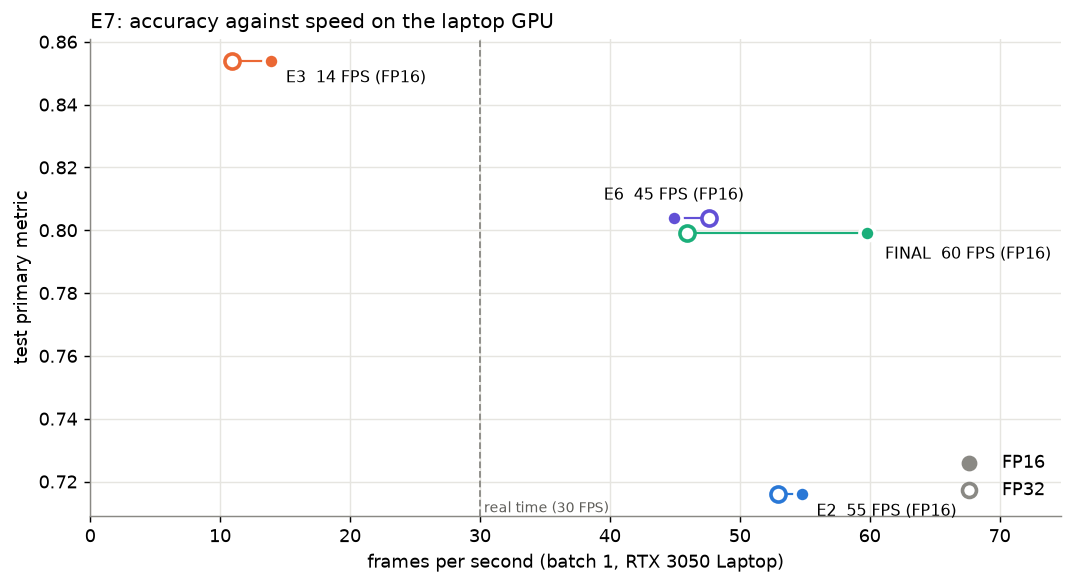

In [6]:
from IPython.display import Image as _Img, display
display(_Img(filename=str(RESULTS / "E7" / "figures" / "speed_accuracy.png"), width=720))

## 5. RQ3: how much does a random split overestimate performance?

FINAL and E5 use exactly the same recipe; only the split differs. FINAL is tested on drives it never saw; E5 is tested
on random images, whose neighbouring frames from the same drives were in training.

In [7]:
rq3 = pd.DataFrame({
    "FINAL (split by drive)": {"val primary": recs["FINAL"]["val_primary_mAP50_mod"], "test primary": recs["FINAL"]["test_primary_mAP50_mod"],
                               "test Cyclist": recs["FINAL"]["test_AP50_Cyclist_moderate"], "best epoch": recs["FINAL"]["best_epoch"],
                               "epochs run": recs["FINAL"]["epochs_run"]},
    "E5 (random split)": {"val primary": recs["E5"]["val_primary_mAP50_mod"], "test primary": recs["E5"]["test_primary_mAP50_mod"],
                          "test Cyclist": recs["E5"]["test_AP50_Cyclist_moderate"], "best epoch": recs["E5"]["best_epoch"],
                          "epochs run": recs["E5"]["epochs_run"]}})
rq3["overestimate"] = (rq3.iloc[:, 1] - rq3.iloc[:, 0])[["val primary", "test primary", "test Cyclist"]]
display(rq3.round(3))
display(pd.read_csv(RESULTS / "E5" / "near_duplicate_breakdown.csv").round(3))

,FINAL (split by drive),E5 (random split),overestimate
val primary,0.758,0.947,0.189
test primary,0.799,0.964,0.165
test Cyclist,0.631,0.963,0.331
best epoch,3.000,50.000,NaN
epochs run,13.000,50.000,NaN


,subset,images,primary_mAP50_mod,mAP50_all8
0,near-duplicate (<= 2 frames),853,0.968,0.955
1,no close neighbour (> 2 frames),270,0.956,0.925


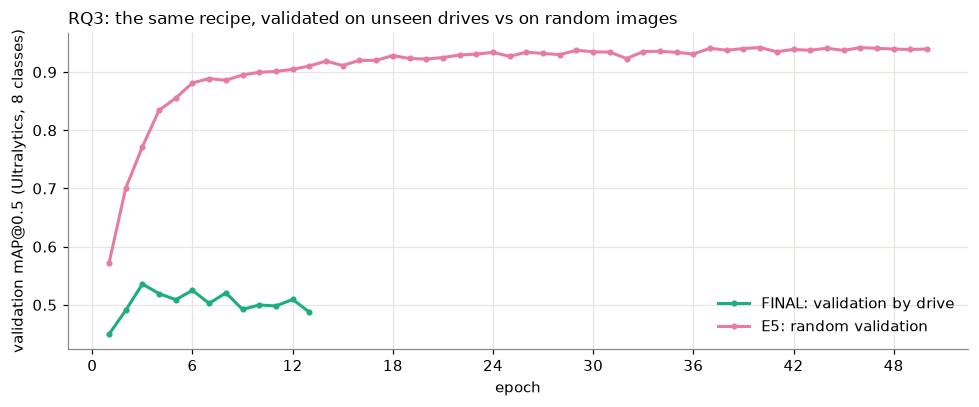

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for e in ["FINAL", "E5"]:
    h = pd.read_csv(RESULTS / e / "history.csv")
    h.columns = h.columns.str.strip()
    ax.plot(h.epoch, h["metrics/mAP50(B)"], color=MODEL_C[e], marker="o", ms=3,
            label=f"{e}: " + ("validation by drive" if e == "FINAL" else "random validation"))
ax.set_xlabel("epoch"); ax.set_ylabel("validation mAP@0.5 (Ultralytics, 8 classes)"); ax.legend(loc="lower right")
ax.set_title("RQ3: the same recipe, validated on unseen drives vs on random images", loc="left")
_save(fig, "summary", "rq3_validation_curves")

## 6. RQ4: bad weather, and does augmentation help?

Both models on the test set with simulated fog, rain and low light at three severities (notebook 07).

model                  E6  FINAL  drop FINAL  drop E6  E6 - FINAL
weather   severity                                               
fog       1         0.772  0.736      -0.062   -0.032       0.036
          2         0.699  0.655      -0.144   -0.105       0.045
          3         0.497  0.437      -0.361   -0.308       0.059
low_light 1         0.747  0.753      -0.045   -0.057      -0.006
          2         0.563  0.504      -0.295   -0.241       0.060
          3         0.405  0.226      -0.573   -0.399       0.179
rain      1         0.784  0.772      -0.026   -0.020       0.012
          2         0.687  0.652      -0.147   -0.118       0.035
          3         0.444  0.402      -0.397   -0.360       0.043

clean: FINAL 0.799, E6 0.804 | mean over the 9 corrupted sets: FINAL 0.571, E6 0.622


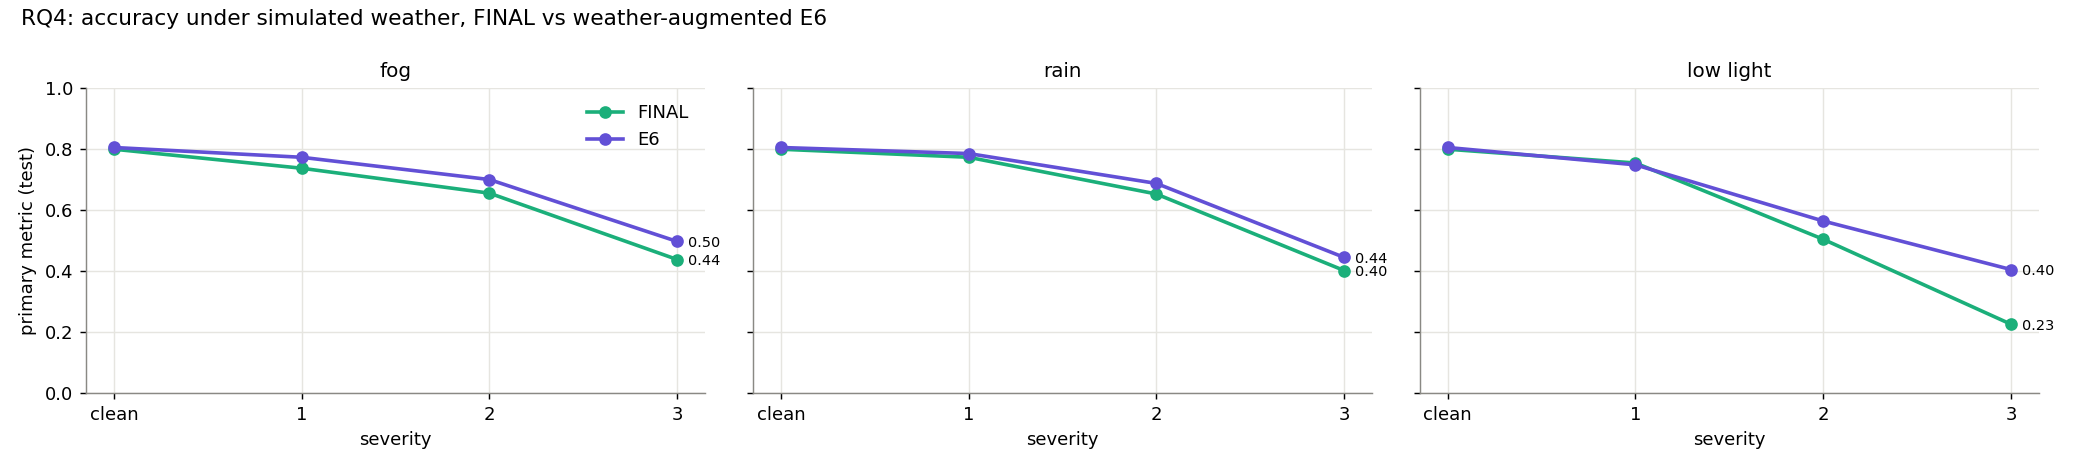

In [9]:
rob = pd.read_csv(RESULTS / "E8" / "robustness.csv")
clean = rob[rob.weather == "clean"].set_index("model").primary_mAP50_mod
rq4 = rob[rob.weather != "clean"].pivot_table(index=["weather", "severity"], columns="model", values="primary_mAP50_mod")
rq4["drop FINAL"] = rq4.FINAL - clean["FINAL"]
rq4["drop E6"] = rq4.E6 - clean["E6"]
rq4["E6 - FINAL"] = rq4.E6 - rq4.FINAL
display(rq4.round(3))
print(f"clean: FINAL {clean['FINAL']:.3f}, E6 {clean['E6']:.3f} | mean over the 9 corrupted sets: "
      f"FINAL {rq4.FINAL.mean():.3f}, E6 {rq4.E6.mean():.3f}")
display(_Img(filename=str(RESULTS / "E8" / "figures" / "robustness.png"), width=900))

## 7. Training behaviour: early overfitting

The epoch with the best validation score, for every model trained on the drive-grouped split, and for E5.

In [10]:
tr = log.loc[["E2", "E3", "E4a_ref", "E4b_img960", "E4c_rfs", "E4d_combined", "E4e_lr002", "FINAL", "E6", "E5"],
             ["best_epoch", "epochs_run", "train_hours", "val_primary_mAP50_mod"]]
tr.columns = ["best epoch", "epochs run", "train hours", "val primary"]
print(f"total GPU training time: {log.train_hours.fillna(0).sum():.1f} h")
tr.round(3)

total GPU training time: 8.4 h


,best epoch,epochs run,train hours,val primary
exp_id,,,,
E2,2.0,12.0,0.214,0.697
E3,2.0,10.0,1.792,0.812
E4a_ref,2.0,12.0,0.218,0.670
E4b_img960,2.0,12.0,0.432,0.787
E4c_rfs,2.0,12.0,0.269,0.682
E4d_combined,18.0,25.0,1.133,0.732
E4e_lr002,3.0,13.0,0.601,0.779
FINAL,3.0,13.0,0.624,0.758
E6,3.0,13.0,0.639,0.748


## 8. Answers to the research questions

**RQ1. How much does training on KITTI help compared with a general-purpose pretrained detector?**
A lot. The same YOLOv8s goes from **0.542** (COCO weights only) to **0.716** after fine-tuning (E2) and **0.799** after
tuning (FINAL): **+0.257** on the primary metric. Cars were already good with COCO weights (0.930 → 0.967); the gain
is in pedestrians (0.687 → 0.797) and above all **cyclists (0.008 → 0.631)**, a class COCO does not have.

**RQ2. Which approach gives the best balance between accuracy and speed; does it run in real time on a laptop GPU?**
**Faster R-CNN is the most accurate (0.854) but not real time (11–14 FPS)** on the RTX 3050 Laptop GPU. **The tuned
YOLOv8s (FINAL) is real time (45–60 FPS) at 0.799**, 0.055 below Faster R-CNN, almost all of it on cyclists (0.631 vs
0.779). For a driver-assistance system that has to react to every frame, FINAL is the better balance, and it is the
model the app uses. The largest single gain in tuning came from the input size (640 → 960 px: +0.117 on validation,
mostly cyclists); oversampling rare classes helped only slightly.

**RQ3. How much does a random image-level split overestimate performance?**
By **0.165** on the test set (0.964 vs 0.799) and 0.189 on validation; for cyclists by 0.331. With a random split the
validation score kept rising for all 50 epochs, so it rewards memorising the training drives instead of warning
against it. The leak is not only adjacent frames: random-test images with no training frame within 2 frames still
score 0.956. **Splitting by drive is necessary** for an honest estimate.

**RQ4. How much does accuracy drop under simulated fog, rain and low light; can augmentation reduce the drop?**
Mild conditions cost little (0.03–0.06), but at the strongest severity FINAL drops from 0.799 to **0.437 (fog),
0.402 (rain) and 0.226 (low light)**. Weather augmentation during training (E6) **keeps the clean score (0.804)** and
reduces the drop in 8 of the 9 corrupted sets; averaged over all 9 it scores **0.622 against 0.571**, and in the
darkest setting **0.405 against 0.226**. Cyclists and pedestrians suffer most; cars stay detectable.

## 9. Conclusions and limitations

* **The deployed model** is FINAL (YOLOv8s, 960 px, repeat-factor sampling, learning rate 0.002): 0.799 on unseen
  drives (Car 0.967, Pedestrian 0.797, Cyclist 0.631) at about 60 FPS on a laptop GPU. The pipeline was checked to
  reproduce that score.
* **Small and occluded vulnerable road users are the main weakness:** only about 1 in 5 pedestrians of 25–40 px
  height is found (notebook 05). Almost half of the false alarms fall on unlabelled (DontCare) objects.
* **Every model overfits the training drives within 2–3 epochs** (validation peaks early, training loss keeps falling).
  141 drives is little scene variety; more drives would help more than more epochs.
* **Limitations.** One training run per setting (single seed): differences below about 0.02 are within run-to-run
  noise (FINAL and E4e, identical settings, differ by 0.021 on validation). The tuning rule compared only the
  round-2 trials, so 960 px alone (0.787) was not chosen over E4e (0.779), a gap inside that noise. The weather is
  simulated, and the same family of effects is used in E6's training, so RQ4 measures robustness to these
  corruptions, not to real fog or night driving. Speeds were measured on one laptop and vary by up to ~14 FPS between
  repeats. Distances in the app are rough monocular estimates.